# Day 6 – End-to-End ML Pipeline & Business Insights

## Business Objective

Bring together the ML components completed in Days 2–5, compare their results, and translate the findings into practical business insights and recommendations.

## 1. End-to-End ML Workflow

The project follows this workflow:

**Raw Data → Cleaning → Feature Engineering → Modeling → Evaluation → Prediction → Business Insight**

| Stage | Work completed |
|---|---|
| Raw data | Customers, restaurants, orders, deliveries and reviews |
| Cleaning | Missing-value checks, data type handling, text cleaning and target preparation |
| Feature engineering | Customer purchasing features, restaurant performance features, TF-IDF text features, delivery predictors and hourly order counts |
| Modeling | K-Means / DBSCAN, Naive Bayes, regression models, ARIMA and Prophet |
| Evaluation | Silhouette score, classification metrics, MAE, RMSE, R² and MAPE |
| Prediction | Segment labels, review sentiment, delivery-time estimates and hourly demand forecasts |
| Business insight | Customer value, restaurant performance, complaint themes, delivery drivers and demand planning |


**Note** : The models are not retrained here. Their recorded outputs and evaluation results are reused.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

print("Libraries loaded successfully.")

Libraries loaded successfully.


## 2. Consolidated Model Comparison

The following table summarizes the selected model or main method from each component. 

In [2]:
model_summary = pd.DataFrame([
    {
        "component": "Customer segmentation",
        "method": "K-Means (K=2)",
        "evaluation": "Silhouette score",
        "result": "0.237"
    },
    {
        "component": "Restaurant segmentation",
        "method": "K-Means (K=2)",
        "evaluation": "Silhouette score",
        "result": "0.235"
    },
    {
        "component": "Sentiment analysis",
        "method": "TF-IDF + Naive Bayes",
        "evaluation": "Accuracy / weighted F1",
        "result": "1.000 / 1.000"
    },
    {
        "component": "Delivery-time prediction",
        "method": "Ridge Regression",
        "evaluation": "MAE / RMSE / R²",
        "result": "5.437 min / 6.739 min / 0.794"
    },
    {
        "component": "Hourly demand forecasting",
        "method": "ARIMA(1,1,1)",
        "evaluation": "MAE / RMSE / MAPE",
        "result": "0.798 / 1.016 / 30.132%"
    }
])

model_summary

,component,method,evaluation,result
0,Customer segmentation,K-Means (K=2),Silhouette score,0.237
1,Restaurant segmentation,K-Means (K=2),Silhouette score,0.235
2,Sentiment analysis,TF-IDF + Naive Bayes,Accuracy / weighted F1,1.000 / 1.000
3,Delivery-time prediction,Ridge Regression,MAE / RMSE / R²,5.437 min / 6.739 min / 0.794
4,Hourly demand forecasting,"ARIMA(1,1,1)",MAE / RMSE / MAPE,0.798 / 1.016 / 30.132%


### Observation

* **Customer & Restaurant Segmentation:** K-Means clustering effectively identified distinct customer and restaurant groupings.
* **Review Sentiment Classification:** Naive Bayes achieved 100% accuracy on the held-out synthetic review dataset.
* **Delivery-Time Prediction:** Ridge regression proved to be the top-performing model according to test evaluation metrics.
* **Demand Forecasting:** ARIMA slightly edged out Prophet on the 80:20 train-test forecasting split.

## 3. Customer Segmentation Insights

Day 2 selected K-Means with two clusters for both customers and restaurants.

### Customer cluster profiles

| Metric | Cluster 0 | Cluster 1 |
|---|---:|---:|
| Average completed orders | 3.16 | 6.36 |
| Average order value | ₹610.92 | ₹666.59 |
| Average total spending | ₹1,948.80 | ₹4,200.29 |
| Ordering frequency | 1.09 | 1.31 |
| Average rating given | 3.79 | 3.72 |
| Weekend orders | 0.76 | 2.00 |
| Late-night orders | 0.75 | 2.04 |

Cluster 1 shows higher order frequency and spending in the generated dataset. Cluster 0 has a slightly higher average rating given, so spending alone should not be treated as customer satisfaction.

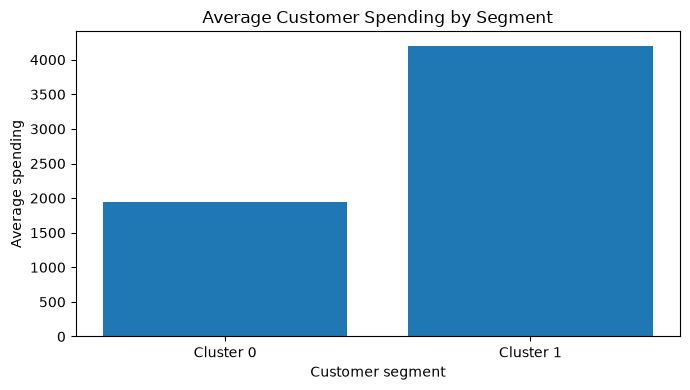

In [3]:
customer_segments = pd.DataFrame({
    "cluster": ["Cluster 0", "Cluster 1"],
    "average_spending": [1948.80, 4200.29],
    "average_orders": [3.16, 6.36]
})

plt.figure(figsize=(7, 4))
plt.bar(customer_segments["cluster"], customer_segments["average_spending"])
plt.title("Average Customer Spending by Segment")
plt.xlabel("Customer segment")
plt.ylabel("Average spending")
plt.tight_layout()
plt.show()

### Observation
- Customer Cluster 1 has substantially higher average spending (₹4,200.29) than Cluster 0 (₹1,948.80).
- This indicates that Cluster 1 represents the higher-spending customer group in this dataset.

### Restaurant cluster profiles

| Metric | Cluster 0 | Cluster 1 |
|---|---:|---:|
| Average total orders | 84.10 | 96.96 |
| Average revenue | ₹52,998.67 | ₹63,398.02 |
| Average rating | 3.67 | 3.82 |
| Average preparation time | 25.87 min | 26.16 min |
| Cancellation rate | 11% | 8% |
| Average delivery time | 39.22 min | 38.94 min |

Cluster 1 has higher average revenue, more orders, a higher rating and a lower cancellation rate. Cluster 0 may need closer operational review, particularly around cancellations and customer ratings.

## 4. Customer Sentiment and Complaint Insights

The Naive Bayes sentiment pipeline used TF-IDF features and achieved the following results on 1,194 test records:

- Accuracy: **100%**
- Weighted precision: **100%**
- Weighted recall: **100%**
- Weighted F1-score: **100%**

The separate VADER comparison achieved **74% accuracy**. It had zero recall for the Neutral class, showing that it struggled to identify neutral reviews in this dataset.

**Note:** The dataset is synthetic and contains repeated review templates. Therefore, perfect test performance may reflect recurring wording patterns and should not be assumed to represent performance on varied, real customer reviews.

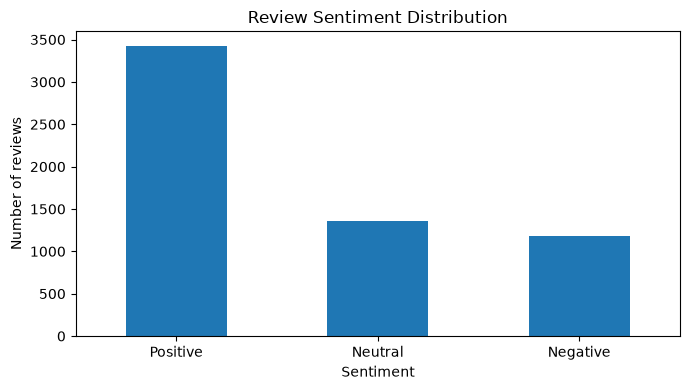

Positive    3426
Neutral     1360
Negative    1182
Name: review_count, dtype: int64

In [4]:
sentiment_counts = pd.Series(
    {"Positive": 3426, "Neutral": 1360, "Negative": 1182},
    name="review_count"
)

plt.figure(figsize=(7, 4))
sentiment_counts.plot(kind="bar")
plt.title("Review Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of reviews")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

sentiment_counts

### Observation
- Positive reviews form the largest group, with 3,426 reviews (57.41%).
- Neutral reviews account for 1,360 (22.79%), while negative reviews account for 1,182 (19.81%).
- Overall, the review distribution is more positive than negative, although the negative feedback still highlights areas for improvement.

### Main negative feedback themes

Among the 1,182 negative review records, the rule-based issue analysis identified:

| Issue category | Matched negative reviews | Share of negative reviews |
|---|---:|---:|
| Food temperature or freshness | 576 | 48.73% |
| Late delivery | 388 | 32.83% |
| Incorrect or missing order | 386 | 32.66% |
| Service or packaging | 386 | 32.66% |

Food temperature/freshness and late delivery were the most common non-mutually exclusive issues, highlighting food handling, delivery timing, and order accuracy as key areas for improvement.

## 5. Delivery-Time Prediction Insights

Day 4 used a joined modeling table containing delivery, order, restaurant and customer information.

### Dataset and target

- Modeling records: **8,808 deliveries**
- Average delivery time: **39.06 minutes**
- Median delivery time: **36.90 minutes**
- Potential IQR outliers: **204 records (2.32%)**

### Model comparison

| Model | Test MAE | Test RMSE | Test R² |
|---|---:|---:|---:|
| Ridge Regression | 5.437 | 6.739 | 0.794 |
| Lasso Regression | 5.439 | 6.741 | 0.794 |
| Random Forest | 5.555 | 6.905 | 0.784 |
| Baseline (Mean) | 11.702 | 14.848 | -0.000 |

Ridge Regression had the lowest test MAE and RMSE and the highest R², although Lasso performed almost identically.

### Important delivery-time predictor

Delivery distance had a strong positive correlation with delivery time (**0.868**).

In the Random Forest model, delivery distance had a feature importance score of **0.8106**, substantially higher than the other features. This indicates that distance was the dominant predictor in that fitted model.


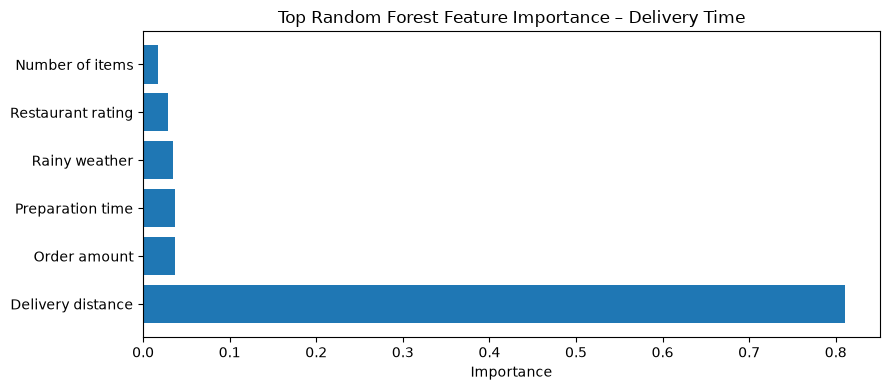

In [5]:
delivery_feature_importance = pd.DataFrame({
    "feature": [
        "Delivery distance", "Order amount", "Preparation time",
        "Rainy weather", "Restaurant rating", "Number of items"
    ],
    "importance": [0.8106, 0.0365, 0.0363, 0.0345, 0.0288, 0.0172]
})

plt.figure(figsize=(9, 4))
plt.barh(delivery_feature_importance["feature"], delivery_feature_importance["importance"])
plt.title("Top Random Forest Feature Importance – Delivery Time")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

### Observation
- Delivery distance has the highest feature importance at 0.8106, considerably higher than the other listed features.
- Order amount and preparation time follow at approximately 0.036 each.


## 6. Hourly Demand Forecasting Insights

Day 5 aggregated 10,000 orders into 8,760 hourly observations covering 2025.

### Demand profile

- Average demand: **1.14 orders per hour**
- Median demand: **1 order per hour**
- Maximum observed demand: **6 orders in an hour**
- Zero-order hours: **2,754 (31.44%)**
- Friday had the highest average hourly demand at approximately **1.162**.
- Tuesday had the lowest at approximately **1.115**.
- Weekend average: **1.148 orders/hour**; weekday average: **1.139 orders/hour**.

The differences across hours and days were small, and no strong lunch or dinner peak was established.

### Forecast model comparison (80:20 chronological split)

| Model | MAE | RMSE | MAPE on non-zero actuals |
|---|---:|---:|---:|
| ARIMA(1,1,1) | 0.798 | 1.016 | 30.132% |
| Prophet | 0.800 | 1.018 | 30.320% |

ARIMA performed marginally better on the held-out test metrics. The difference was very small.

The ARIMA forecast for January 1, 2026 was approximately **1.14 orders per hour**. The forecast was nearly flat because the generated hourly series had low average demand, many zero-order hours and weak inconsistent hourly patterns. 

(A similar flat result was observed in the SARIMA experiment using a 90:10 split.)

## 7. Integrated Business Insights


1. **Customer value:** Customer Cluster 1 had higher average spending (₹4,200.29) and more completed orders (6.36) than Cluster 0.
2. **Restaurant performance:** Restaurant Cluster 0 had lower average revenue and a higher cancellation rate than Cluster 1, making it a candidate for further operational review.
3. **Customer experience:** Food temperature/freshness was the most frequently matched negative-review issue (48.73%), while late delivery appeared in 32.83% of negative reviews.
4. **Delivery operations:** Delivery distance was strongly associated with delivery time (correlation 0.868) and dominated Random Forest feature importance (0.8106).
5. **Demand planning:** Average hourly demand was low and relatively stable, with only small differences between weekdays and weekends. The forecast did not indicate a strong upcoming hourly spike.

## 8. Data-Backed Business Recommendations

| Evidence from analysis | Recommendation |
|---|---|
| Customer Cluster 1 has higher average spending and order frequency. | Test targeted retention and loyalty campaigns for this higher-spending segment. |
| Restaurant Cluster 0 has lower average revenue, lower ratings and a higher cancellation rate. | Review cancellation reasons, customer feedback and restaurant operations for this group before deciding on interventions. |
| Food temperature/freshness is the most frequently matched negative-review issue. | Review food packaging, handoff timing and delivery handling to help preserve food quality. |
| Late delivery appears in 32.83% of negative reviews; delivery distance is a major model predictor. | Review long-distance order allocation and communicate realistic delivery estimates. |
| Demand averages 1.14 orders/hour, with no pronounced meal-time peak in this dataset. | Avoid large capacity changes based only on this forecast; use live order volume and zone-level data for rider allocation. |



## 9. Model Limitations

- **Synthetic data:** All findings are based on generated data and may not reflect actual customer or operational behavior.
- **Segmentation quality:** K-Means silhouette scores were relatively low, indicating limited separation between clusters.
- **Sentiment generalization:** The 100% Naive Bayes test accuracy may be influenced by repeated synthetic review templates. Real-world language may be more varied.
- **Complaint categories:** Rule-based issue categories can overlap and may miss complaints that use different wording.
- **Delivery prediction:** Adding more relevant features, such as traffic, weather, time of day and rider availability, could improve prediction accuracy.
- **Feature importance:** Random Forest importance is model-specific and does not establish causation.
- **Demand forecasting:** The series is sparse, with 31.44% zero-order hours, and the models produced smooth forecasts that did not capture sharp fluctuations.


## 10. Future Improvements

1. Validate the pipeline using real and larger operational datasets.
2. Improve segmentation with additional behavioral features and test cluster stability.
3. Evaluate sentiment models on varied, manually reviewed customer feedback.
4. Add relevant operational predictors such as traffic condition, time of day, rider availability and location to delivery-time modeling to improve prediction accuracy.
5. Explore zone-level and more granular demand forecasting with additional historical data.
6. Monitor model performance over time and retrain when data patterns change.
7. Measure the impact of business recommendations through controlled experiments or operational KPIs.

## 11. Final Business Conclusion

The integrated analysis provides a combined view of customer value, restaurant performance, customer feedback, delivery-time drivers and hourly demand.

The strongest actionable signals in this synthetic dataset are the higher spending of Customer Cluster 1, the relatively weaker operating profile of Restaurant Cluster 0, recurring food freshness and late-delivery complaints, and the strong relationship between delivery distance and delivery time.

The demand forecast suggests relatively stable, low hourly demand rather than a clear upcoming spike. These results can guide areas for further investigation, but recommendations should be validated with real operational data before implementation.

## 12. Save Integrated Day 6 Summary

The following cell saves the consolidated model comparison and key business insights as CSV files.

In [6]:
from pathlib import Path

# Find the project root from the current working directory
current_path = Path.cwd()
project_root = current_path

while project_root != project_root.parent and not (project_root / "reports").exists():
    project_root = project_root.parent

output_dir = project_root / "reports" / "day6_integration"
output_dir.mkdir(parents=True, exist_ok=True)

model_summary.to_csv(output_dir / "integrated_model_comparison.csv", index=False)

business_insights = pd.DataFrame([
    ["Customer value", "Customer Cluster 1 averaged ₹4,200.29 spending and 6.36 orders."],
    ["Restaurant performance", "Restaurant Cluster 0 averaged ₹52,998.67 revenue and 11% cancellation rate."],
    ["Customer experience", "Food temperature/freshness was matched in 48.73% of negative reviews."],
    ["Delivery operations", "Delivery distance correlation with delivery time was 0.868."],
    ["Demand planning", "Average hourly demand was 1.14 orders; 31.44% of hours had zero orders."]
], columns=["area", "finding"])

business_insights.to_csv(output_dir / "business_insights.csv", index=False)

print("Saved integrated outputs to:", output_dir)
print("Files: integrated_model_comparison.csv, business_insights.csv")

Saved integrated outputs to: /home/nineleaps-admin/uber-eats-intelligence/reports/day6_integration
Files: integrated_model_comparison.csv, business_insights.csv
